In [2]:
from memoria_icm.datos import *
import numpy as np

df, df_resumen = cargar_datos()
#df, df_resumen = filtar_por_duracion(10)

Datos cargados. Trackeo: (44324, 28), Resumen: (192, 42)


In [15]:
nans1 = df[df['id'] == 320]
nans2 = df[df['id'] == 219]

In [ ]:
nans_por_id = df.groupby('id').apply(lambda x: x.isna().sum())

df['v_calc'] = df.groupby('id').apply(lambda g: np.sqrt(g['x'].diff()**2 + g['y'].diff()**2) / g['t'].diff()).reset_index(level=0, drop=True)
df['vx_calc'] = df.groupby('id')['x'].diff() / df.groupby('id')['t'].diff()
df['vy_calc'] = df.groupby('id')['y'].diff() / df.groupby('id')['t'].diff()
df['delta_vx'] = df['vx_calc'] - df['vx'] if 'vx' in df.columns else np.nan
df['delta_vy'] = df['vy_calc'] - df['vy'] if 'vy' in df.columns else np.nan
df['delta_velocidad'] = df['v_calc'] - df['v'] if 'v' in df.columns else np.nan

C:\Users\franc\AppData\Local\Temp\ipykernel_14740\623309927.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  nans_por_id = df.groupby('id').apply(lambda x: x.isna().sum())


        id          t         x         y        vx        vy         v  \
0        0   0.000000  1.976667 -0.624416       NaN       NaN       NaN   
1        0   0.073174  1.981245 -0.629966 -0.030119 -0.122312  0.125966   
2        0   0.123811  1.972938 -0.639559 -0.059602 -0.092332  0.109898   
3        0   0.181472  1.974790 -0.639965  0.000456 -0.021718  0.021723   
4        0   0.224938  1.972984 -0.641756  0.041020 -0.068821  0.080119   
...    ...        ...       ...       ...       ...       ...       ...   
86195  320  15.362240  2.660554 -3.178143 -0.062044 -0.000735  0.062048   
86196  320  15.418690  2.656156 -3.176854 -0.088877  0.020600  0.091234   
86197  320  15.463080  2.651592 -3.176066 -0.067448  0.006764  0.067787   
86198  320  15.510260  2.649979 -3.176235 -0.041035  0.006275  0.041512   
86199  320  15.569050  2.647243 -3.175401       NaN       NaN       NaN   

             ax        ay         a  ...   theta_v   curvatura  \
0           NaN       NaN       N

C:\Users\franc\AppData\Local\Temp\ipykernel_14740\623309927.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df['v_calc'] = df.groupby('id').apply(lambda g: np.sqrt(g['x'].diff()**2 + g['y'].diff()**2) / g['t'].diff()).reset_index(level=0, drop=True)


In [22]:
df = pd.concat([df.iloc[:, :7], df.iloc[:, -6:]], axis=1)
df

,id,t,x,y,vx,vy,v,v_calc,vx_calc,vy_calc,delta_vx,delta_vy,delta_velocidad
0,0,0.000000,1.976667,-0.624416,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0,0.073174,1.981245,-0.629966,-0.030119,-0.122312,0.125966,0.098320,0.062563,-0.075846,0.092682,0.046466,-0.027646
2,0,0.123811,1.972938,-0.639559,-0.059602,-0.092332,0.109898,0.250613,-0.164051,-0.189458,-0.104450,-0.097126,0.140716
3,0,0.181472,1.974790,-0.639965,0.000456,-0.021718,0.021723,0.032881,0.032119,-0.007038,0.031663,0.014681,0.011158
4,0,0.224938,1.972984,-0.641756,0.041020,-0.068821,0.080119,0.058509,-0.041550,-0.041194,-0.082570,0.027627,-0.021609
...,...,...,...,...,...,...,...,...,...,...,...,...,...
86195,320,15.362240,2.660554,-3.178143,-0.062044,-0.000735,0.062048,0.052638,-0.038016,-0.036408,0.024028,-0.035673,-0.009410
86196,320,15.418690,2.656156,-3.176854,-0.088877,0.020600,0.091234,0.081187,-0.077910,0.022834,0.010968,0.002234,-0.010047
86197,320,15.463080,2.651592,-3.176066,-0.067448,0.006764,0.067787,0.104337,-0.102816,0.017752,-0.035368,0.010988,0.036551
86198,320,15.510260,2.649979,-3.176235,-0.041035,0.006275,0.041512,0.034375,-0.034188,-0.003582,0.006847,-0.009857,-0.007137


<Axes: >

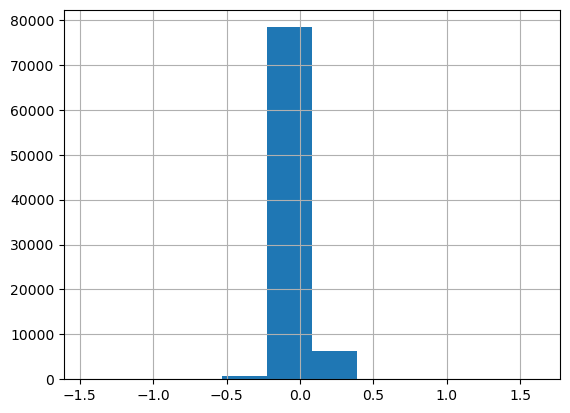

In [23]:
df['delta_vx'].hist()

<Axes: >

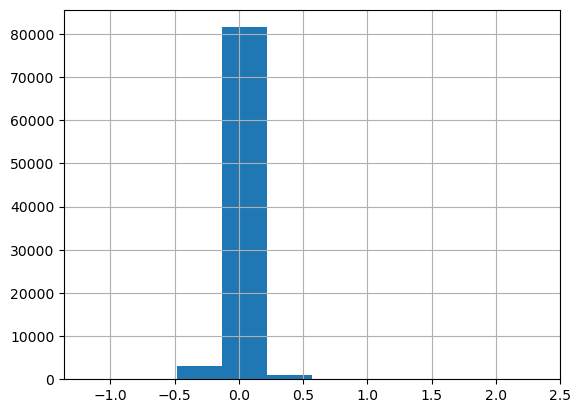

In [24]:
df['delta_vy'].hist()

<Axes: >

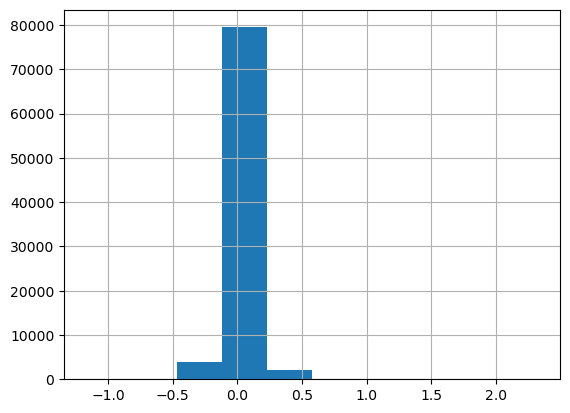

In [25]:
df['delta_velocidad'].hist()

In [10]:
print(nans1.isna().sum()[nans1.isna().sum() > 0])
print(nans1.isna().sum()[nans1.isna().sum() > 0])

vx         1
vy         1
v          1
ax         2
ay         2
a          2
theta_v    1
dtype: int64
vx         1
vy         1
v          1
ax         2
ay         2
a          2
theta_v    1
dtype: int64


In [ ]:
total = np.sum(df_resumen['duracion_video'])
total

total_13s = np.sum(df_resumen[df_resumen['duracion_video'] < 13]['duracion_video'])
conteo_13s = df_resumen[df_resumen['duracion_video'] > 13]['duracion_video'].count()

np.int64(212)

In [8]:
print(1400/4000 *100)

35.0


In [4]:
df['dt'] = df.groupby('id')['t'].diff()

In [10]:
df['dt'].std()

#df['dt'].var()

np.float64(0.01197974725726825)

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 85911 entries, 1 to 86199
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   id               85911 non-null  int64   
 1   t                85911 non-null  float64 
 2   x                85911 non-null  float64 
 3   y                85911 non-null  float64 
 4   vx               85624 non-null  float64 
 5   vy               85616 non-null  float64 
 6   v                85616 non-null  float64 
 7   ax               85048 non-null  float64 
 8   ay               85037 non-null  float64 
 9   a                85037 non-null  float64 
 10  id_ubicacion     85911 non-null  category
 11  especie          85911 non-null  category
 12  tratamiento      85911 non-null  category
 13  salinidad        85911 non-null  category
 14  nombre_archivo   85911 non-null  category
 15  estadio_larval   85911 non-null  category
 16  obs              85911 non-null  category
 17

### Definición de intervalo de tiempo común

Consideramos los percentiles 5 y 95 y luego el RIC.

In [5]:
#con percentiles

duracion_videos = df['duracion_video'].drop_duplicates()

lim_inf = duracion_videos.quantile(0.05)
lim_sup = duracion_videos.quantile(0.95)

lim_sup = 40

df_filtrado_percentiles = df[(df['duracion_video'] >= lim_inf) & (df['duracion_video'] <= lim_sup)]
df_filtrado_percentiles_cantidad = len(df_filtrado_percentiles['id'].drop_duplicates())

print(f'Limite inferior: {lim_inf}, limite superior: {lim_sup}')
print(f'¿Con cuántos videos de los {len(duracion_videos)} me quedo con este método?')
print(f'-> {df_filtrado_percentiles_cantidad}, representando el {df_filtrado_percentiles_cantidad / len(duracion_videos)*100} % del total')

Limite inferior: 7.887301, limite superior: 40
¿Con cuántos videos de los 289 me quedo con este método?
-> 274, representando el 94.80968858131487 % del total


En ambos casos tanto RIC como percentiles me quedo con el ~90% de los datos originales. RIC deja 4 más que percentiles, así que en base a este defino el df filtrado.

Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\general\distribucion_tiempos_maximos.png


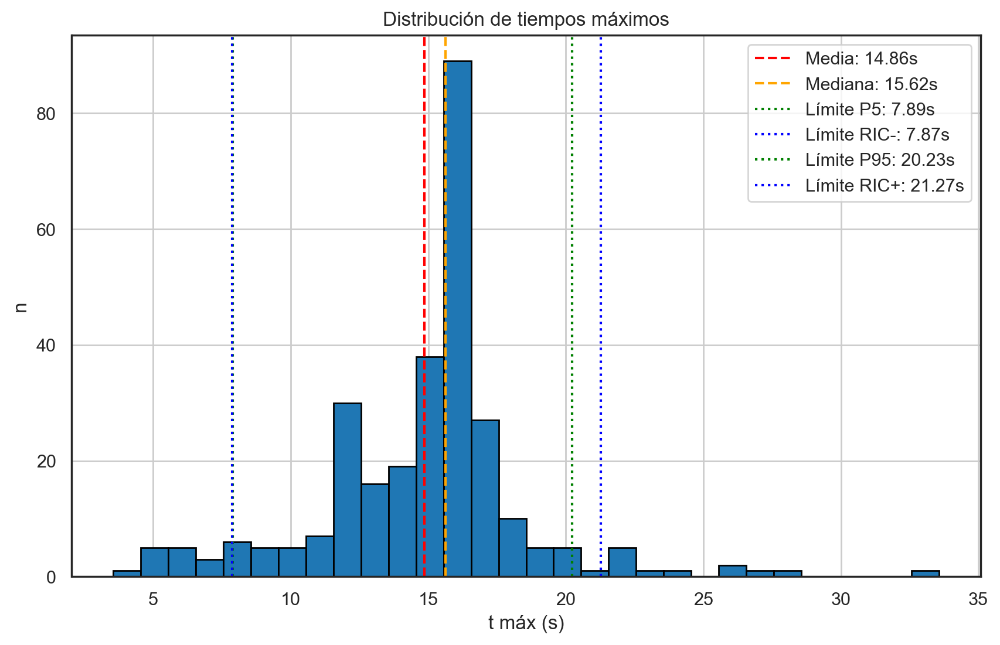

In [53]:
import matplotlib.pyplot as plt
import pathlib

output_dir = pathlib.Path(BASE_DIR) / 'resultados' / 'figuras' / 'tiempos'
output_dir.mkdir(parents=True, exist_ok=True)

file_name = "distribucion_tiempos_maximos.png"
full_path = output_dir / file_name


plt.figure(figsize=(10, 6))
plt.hist(duracion_videos, bins='auto', edgecolor='black')
plt.xlabel('t máx (s)')
plt.ylabel('n')
plt.title('Distribución de tiempos máximos')
plt.axvline(duracion_videos.mean(), color='red', linestyle='--', label=f'Media: {duracion_videos.mean():.2f}s')
plt.axvline(duracion_videos.median(), color='orange', linestyle='--', label=f'Mediana: {duracion_videos.median():.2f}s')
plt.axvline(lim_inf, color='green', linestyle=':', label=f'Límite P5: {lim_inf:.2f}s')
plt.axvline(limite_inferior, color='blue', linestyle=':', label=f'Límite RIC-: {limite_inferior:.2f}s')
plt.axvline(lim_sup, color='green', linestyle=':', label=f'Límite P95: {lim_sup:.2f}s')
plt.axvline(limite_superior, color='blue', linestyle=':', label=f'Límite RIC+: {limite_superior:.2f}s')
plt.legend()
plt.grid(True)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"Figura guardada en: {full_path}")
plt.show()

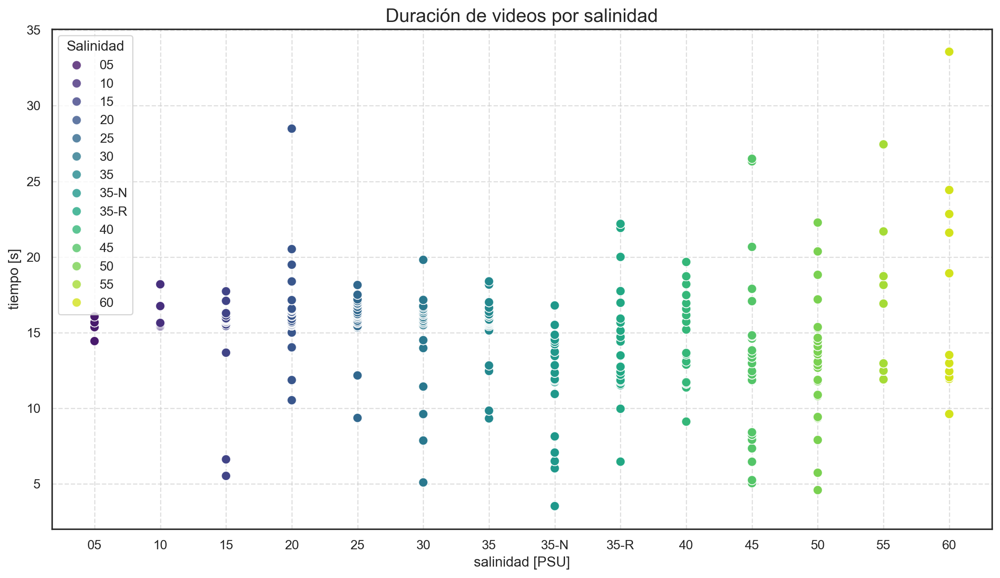

Gráfico guardado en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\general\scatter_duracion_vs_salinidad.png


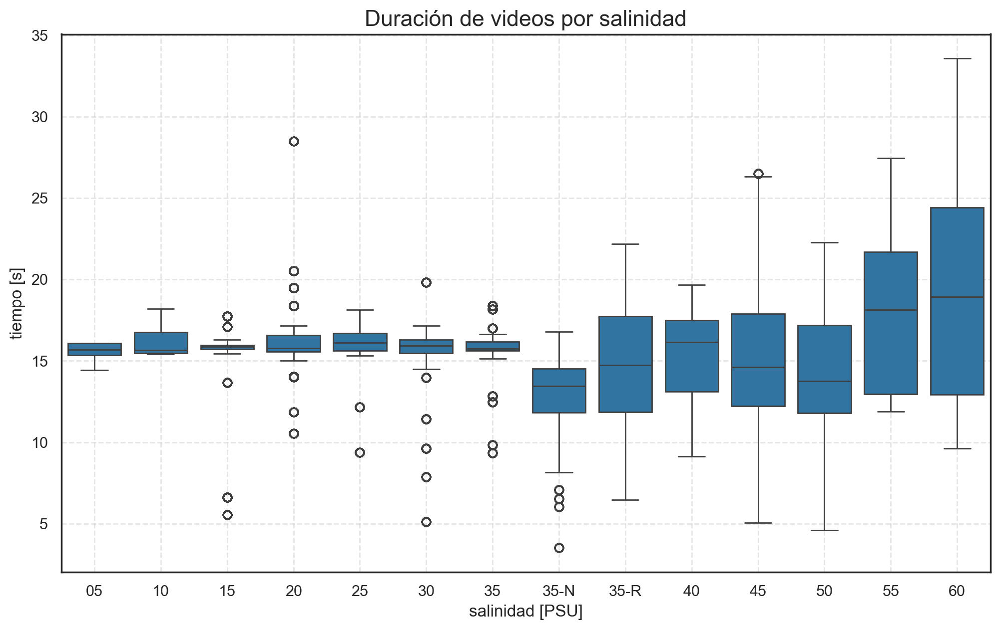

Gráfico guardado en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\general\boxplot_duracion_por_salinidad.png


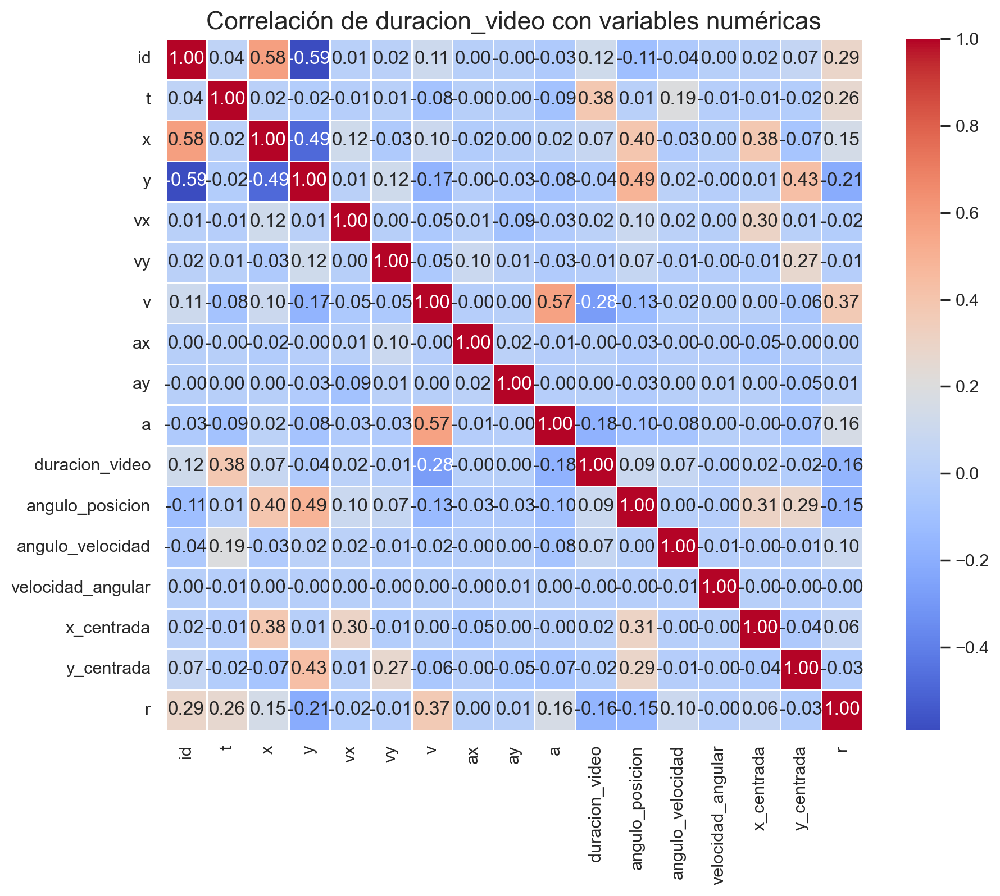

Gráfico guardado en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\general\heatmap_correlacion_variables.png


In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

columna_duracion = 'duracion_video'
columna_salinidad = 'salinidad'

plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x=columna_salinidad, y=columna_duracion, hue=columna_salinidad, palette='viridis', s=60, alpha=0.8)
plt.title('Duración de videos por salinidad', fontsize=16)
plt.xlabel(f'salinidad [PSU]', fontsize=12)
plt.ylabel('tiempo [s]', fontsize=12)
plt.legend(title='Salinidad')
plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.6)

file_path = output_dir / 'scatter_duracion_vs_salinidad.png'
plt.savefig(file_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico guardado en: {file_path}")

plt.figure(figsize=(12, 7))
sns.boxplot(data=df, x=columna_salinidad, y=columna_duracion)
plt.title('Duración de videos por salinidad', fontsize=16)
plt.xlabel('salinidad [PSU]', fontsize=12)
plt.ylabel('tiempo [s]', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

file_path = output_dir / 'boxplot_duracion_por_salinidad.png'
plt.savefig(file_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico guardado en: {file_path}")

df_numeric = df.select_dtypes(include=np.number)
correlation_matrix = df_numeric.corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=.5
)
plt.title('Correlación de duracion_video con variables numéricas', fontsize=16)

file_path = output_dir / 'heatmap_correlacion_variables.png'
plt.savefig(file_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico guardado en: {file_path}")

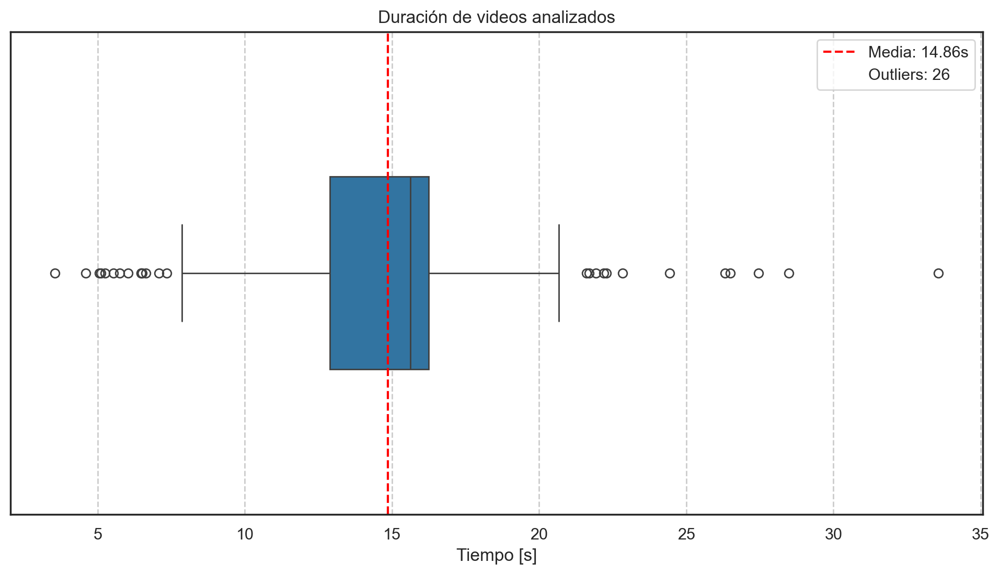

Gráfico guardado en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\general\boxplot_horizontal_con_conteo_outliers.png


In [55]:
import matplotlib.patches as mpatches

plt.figure(figsize=(12, 6))
g = sns.boxplot(x=t_maximo, showfliers=True, width=0.4)

g.set_title('Duración de videos analizados')
g.set_xlabel('Tiempo [s]')

plt.axvline(t_maximo.mean(), color='red', linestyle='--', label=f'Media: {t_maximo.mean():.2f}s')

handles, labels = g.get_legend_handles_labels()
outlier_patch = mpatches.Patch(color='none', label=f'Outliers: {num_outliers}')
handles.append(outlier_patch)

plt.legend(handles=handles)
plt.grid(True, axis='x', linestyle='--')

file_path = output_dir / 'boxplot_horizontal_con_conteo_outliers.png'
plt.savefig(file_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico guardado en: {file_path}")

## **Análisis de tiempos**

In [56]:
id_to_t_set = df.groupby('id')['t'].apply(set) #acá cada fila del df son los tiempos únicos de cada video

t_common_all = set.intersection(*id_to_t_set) #intersección de todos los sets
t_counts = id_to_t_set.apply(len) #tamaños por video

# Qué tan frecuentes son los tiempos en todos los videos
t_global = df['t'].round(4)
t_freqs = Counter(t_global)
df_freqs = pd.DataFrame.from_dict(t_freqs, orient='index', columns=['count'])
df_freqs['t'] = df_freqs.index
df_freqs = df_freqs.sort_values('t')

# Mostrar resumen
print(f"Cantidad total de videos: {len(id_to_t_set)}")
print(f"Cantidad total de tiempos únicos: {len(t_global.unique())}")
print(f"Tiempos comunes a TODOS los videos: {len(t_common_all)}")

Cantidad total de videos: 289
Cantidad total de tiempos únicos: 67346
Tiempos comunes a TODOS los videos: 0


In [57]:
print(min(df['duracion_video']))

3.5393


In [58]:
output_dir = pathlib.Path(BASE_DIR) / 'resultados' / 'figuras' / 'tiempos'
output_dir.mkdir(parents=True, exist_ok=True)

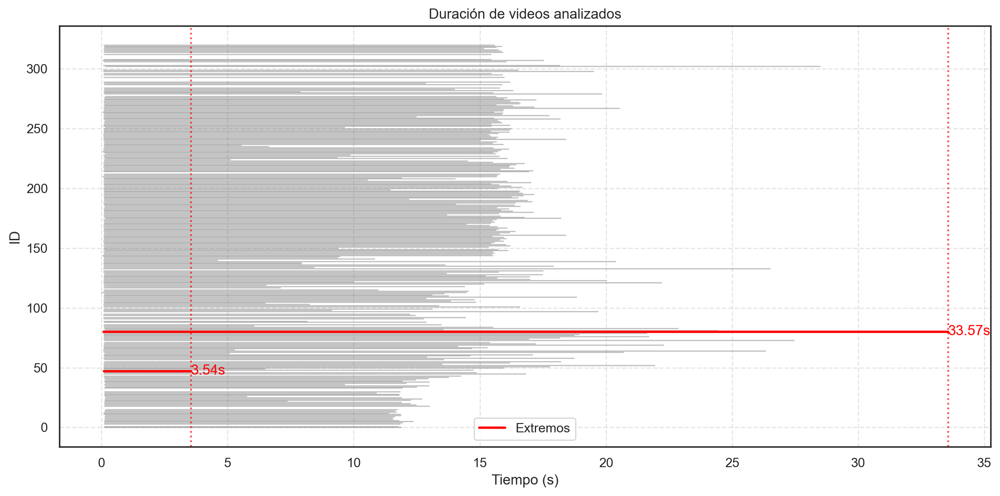

In [59]:
rango_t = df.groupby('id')['t'].agg(['min', 'max', 'count']).reset_index()
rango_t['duracion'] = rango_t['max'] - rango_t['min']  # Calcula duración

mas_corto = rango_t.loc[rango_t['duracion'].idxmin()]
mas_largo = rango_t.loc[rango_t['duracion'].idxmax()]

plt.figure(figsize=(12, 6))

for _, row in rango_t.iterrows():
    plt.plot([row['min'], row['max']], [row['id'], row['id']], 
             color='gray', alpha=0.5, linewidth=1)

plt.plot([mas_corto['min'], mas_corto['max']], [mas_corto['id'], mas_corto['id']], 
         color='red', alpha=1, linewidth=2, label='Extremos')
plt.plot([mas_largo['min'], mas_largo['max']], [mas_largo['id'], mas_largo['id']], 
         color='red', alpha=1, linewidth=2)

plt.axvline(x=mas_corto['max'], color='red', linestyle=':', alpha=0.7)
plt.axvline(x=mas_largo['max'], color='red', linestyle=':', alpha=0.7)

plt.text(mas_corto['max'], mas_corto['id'], f"{mas_corto['max']:.2f}s", 
         ha='left', va='center', color='red')
plt.text(mas_largo['max'], mas_largo['id'], f"{mas_largo['max']:.2f}s", 
         ha='left', va='center', color='red')

plt.xlabel("Tiempo (s)")
plt.ylabel("ID")
plt.title("Duración de videos analizados")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

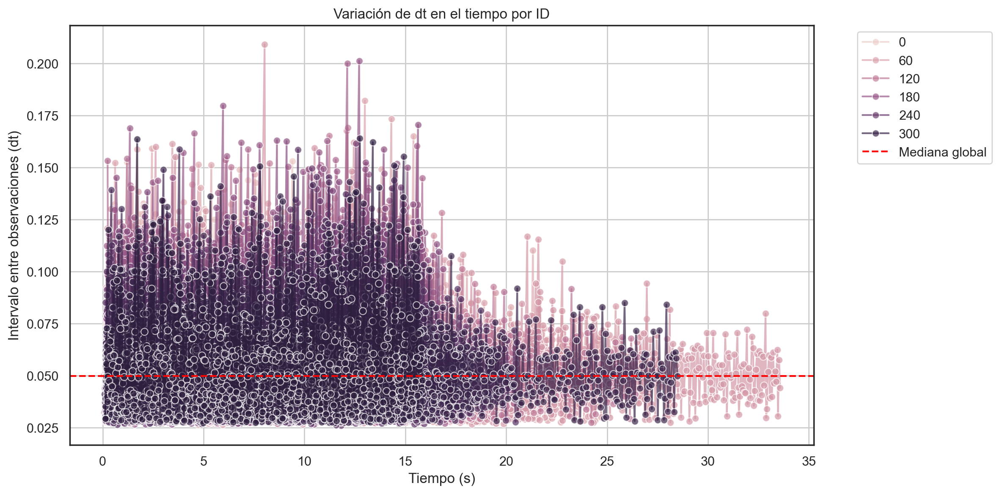

In [60]:
#visualizar los dt

df['dt'] = df.groupby('id')['t'].diff()

plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x='t', y='dt', hue='id', marker='o', alpha=0.7)
plt.axhline(y=df['dt'].median(), color='red', linestyle='--', label='Mediana global')
plt.xlabel("Tiempo (s)")
plt.ylabel("Intervalo entre observaciones (dt)")
plt.title("Variación de dt en el tiempo por ID")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

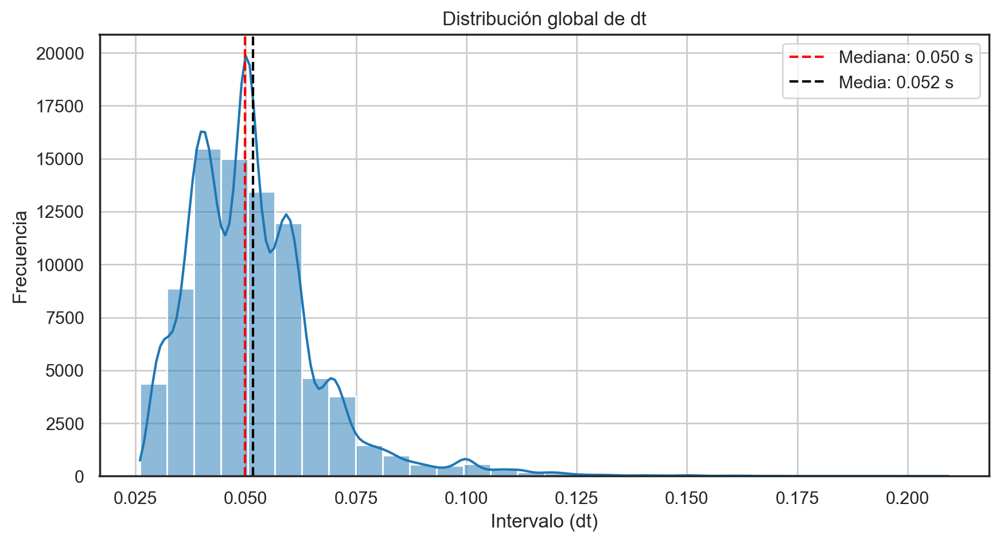

Gráfico guardado en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\tiempos\histograma_densidad_dt.png


In [61]:
plt.figure(figsize=(10, 5))
g = sns.histplot(data=df, x='dt', kde=True, bins=30)
plt.axvline(x = df['dt'].median(), color='red', linestyle='--', label=f'Mediana: {df['dt'].median():.3f} s')
plt.axvline(x=df['dt'].mean(), color='black', linestyle='--', label=f'Media: {df['dt'].mean():.3f} s')
plt.xlabel("Intervalo (dt)")
plt.ylabel("Frecuencia")
plt.title("Distribución global de dt")
plt.legend()
plt.grid(True)

file_path = output_dir / 'histograma_densidad_dt.png'
plt.savefig(file_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico guardado en: {file_path}")

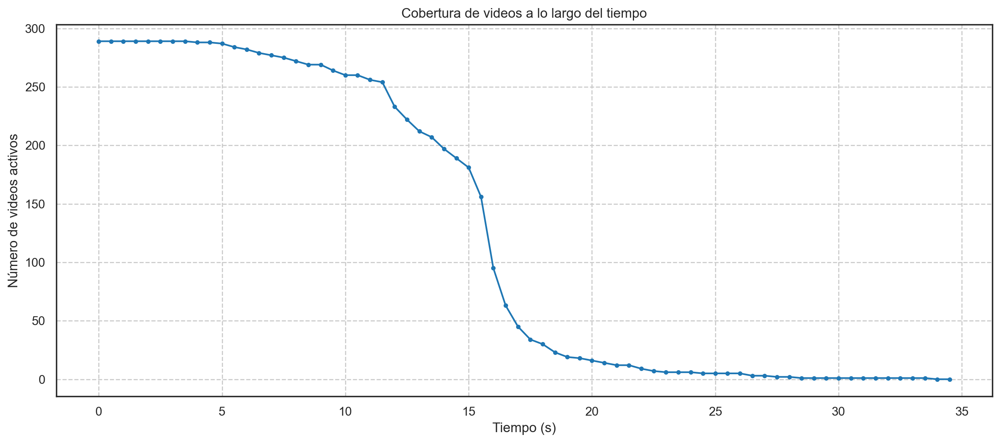

<Figure size 640x480 with 0 Axes>

Gráfico guardado en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\tiempos\lineplot_cobertura_videos_FILTRADO.png


In [62]:
duraciones = df.groupby('id')['t'].max()

# 2. Crear un eje de tiempo para la evaluación (un mallado más razonable).
#    No necesitamos una precisión de 0.0001s, con 0.5s es más que suficiente.
tiempo_grid = np.arange(0, duraciones.max() + 1, 0.5)

# 3. Para cada punto en el tiempo, contar cuántos videos tienen una duración mayor o igual.
#    Es decir, cuántos videos siguen "activos" en ese momento.
videos_activos = [np.sum(duraciones >= t) for t in tiempo_grid]

# 4. Visualizar el resultado
plt.figure(figsize=(15, 6))
plt.plot(tiempo_grid, videos_activos, marker='.', linestyle='-')
plt.xlabel("Tiempo (s)")
plt.ylabel("Número de videos activos")
plt.title("Cobertura de videos a lo largo del tiempo")
plt.grid(True, which='both', linestyle='--')
plt.show()

file_path = output_dir / 'lineplot_cobertura_videos_FILTRADO.png'
plt.savefig(file_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Gráfico guardado en: {file_path}")

## SEGMENTACIÓN DE VIDEOS (AUMENTO DE LA MUESTRA) ##

In [63]:
df = df[(df['duracion_video'] >= limite_inferior) & (df['duracion_video'] <= limite_superior)]

print(len(df['id'].drop_duplicates()))
print(limite_inferior, limite_superior)

print(df.head())

263
7.865225000000002 21.265105
        id         t         x         y        vx        vy         v  ax  \
28130  113  0.000000  1.690929 -0.956505       NaN       NaN       NaN NaN   
28131  113  0.050085  1.690047 -0.955907 -0.028449  0.009955  0.030140 NaN   
36208  144  0.050421  3.207837 -1.974610  0.011637 -0.153980  0.154419 NaN   
83065  307  0.050677  4.424091 -3.676552 -0.184137 -0.026724  0.186066 NaN   
62867  231  0.051020  4.376746 -1.537675 -0.169021  0.150248  0.226147 NaN   

       ay   a  ... video_analizado larva_unica duracion_video angulo_posicion  \
28130 NaN NaN  ...               1           1       14.44751       -0.514793   
28131 NaN NaN  ...               1           1       14.44751       -0.514749   
36208 NaN NaN  ...               1           1       15.51253       -0.551781   
83065 NaN NaN  ...               1           0       17.50818       -0.693377   
62867 NaN NaN  ...               1           1       15.70469       -0.337858   

      angulo

### **3. Pérdida de memoria**

Retorna un dataframe para la variable indicada con los lags que se demora cada individuo en que la autocorrelación baje de un umbral indicado.

In [64]:
from statsmodels.tsa.stattools import acf
import numpy as np
import pandas as pd

umbral = 0.1 #criterio modificable
variable = 'v'

resultados_memoria = []
min_muestreos = df.groupby('id')[variable].apply(lambda x: x.dropna().shape[0]).min()

for id, grupo in df.groupby('id'):
    variable_series = grupo[variable].dropna()
    t_series = grupo.loc[variable_series.index, 't']

    if len(variable_series) < min_muestreos:
        continue

    autocorr = acf(variable_series, nlags=len(variable_series)//2, fft=True)

    metadatos_diccionario = {'id': id}

    for metadato in set(df.columns) - datos_trackeo:
        metadatos_diccionario[metadato] = grupo[metadato].iloc[0]

    for lag, val in enumerate(autocorr):
        if lag > 0 and val < umbral:
            # encontró pérdida de memoria
            metadatos_diccionario.update({
                'lag': lag,
                'tiempo_memoria': t_series.iloc[lag] - t_series.iloc[0]})
            break
    else:
        # no encontró pérdida de memoria, pero así me sigue quedando la cantidad original de entradas
        metadatos_diccionario.update({
            'lag': np.nan,
            'tiempo_memoria': np.nan})
        
    resultados_memoria.append(metadatos_diccionario)

df_memoria = pd.DataFrame(resultados_memoria)
df_memoria['tiempo_memoria'] = df_memoria['tiempo_memoria'].round(7)

In [65]:
print(df_memoria.head())

   id  video_analizado  velocidad_angular tratamiento especie  y_centrada  \
0   0                1        -152.448322           E      CC         0.0   
1   1                1         840.634570           E      CC         0.0   
2   3                1       16506.002396           E      CC         0.0   
3   4                1       -3026.465103           E      CC         0.0   
4   5                1         288.976532           E      CC         0.0   

   duracion_video  angulo_posicion  angulo_velocidad    r  \
0        11.88146        -0.313477         -0.701331  0.0   
1        11.73869        -0.412246          0.725675  0.0   
2        11.83338        -0.871684          5.740477  0.0   
3        11.92390        -0.573182          9.217643  0.0   
4        12.34970        -0.392423          0.612339  0.0   

             estadio_larval  obs salinidad  dt  x_centrada  id_ubicacion  \
0  Larva recién eclosionada    0      35-N NaN         0.0             1   
1  Larva recién ec

In [66]:
T_min = df['duracion_video'].min()

def contar_segmentos(row):
    D = row['duracion_video']
    M = row['tiempo_memoria']
    if M > 0 and not np.isnan(M):
        return int(np.floor((D - T_min) / M)) + 1
    else:
        return 1

df_memoria['n_segmentos'] = df_memoria.apply(contar_segmentos, axis=1)

print(T_min)

7.871665


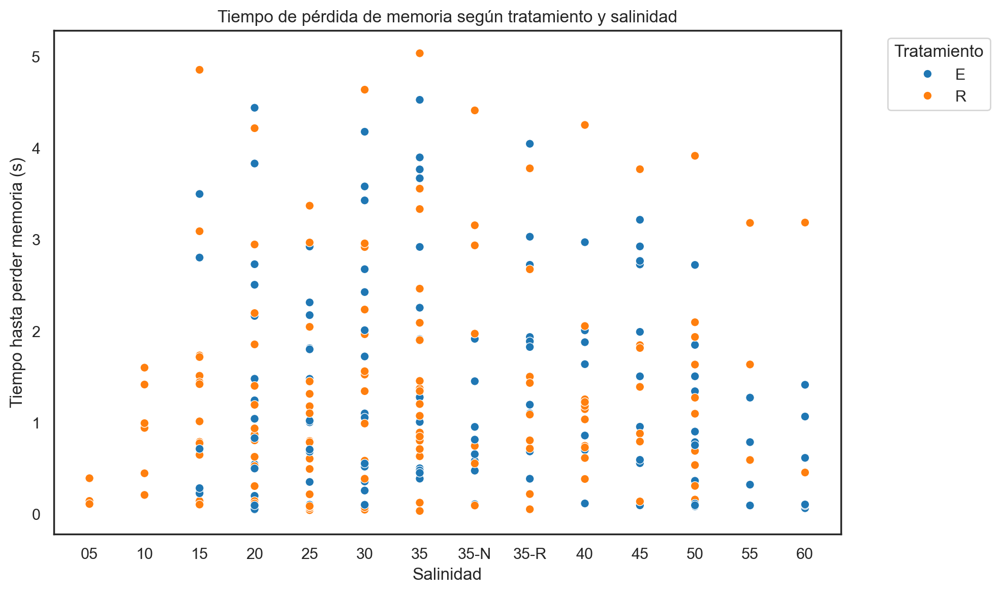

In [67]:
df_memoria = pd.DataFrame(resultados_memoria)

salinidades = orden_salinidades(df_memoria) 
df_memoria['salinidad'] = df_memoria['salinidad'].astype('category')
df_memoria['salinidad'] = df_memoria['salinidad'].cat.set_categories(salinidades, ordered=True)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_memoria, x='salinidad', y='tiempo_memoria', hue='tratamiento')
plt.ylabel('Tiempo hasta perder memoria (s)')
plt.xlabel('Salinidad')
plt.title('Tiempo de pérdida de memoria según tratamiento y salinidad')
plt.legend(title='Tratamiento', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [70]:
display(df_memoria)

,id,video_analizado,velocidad_angular,tratamiento,especie,y_centrada,duracion_video,angulo_posicion,angulo_velocidad,r,estadio_larval,obs,salinidad,dt,x_centrada,id_ubicacion,larva_unica,nombre_archivo,lag,tiempo_memoria
0,0,1,-152.448322,E,CC,0.0,11.88146,-0.313477,-0.701331,0.0,Larva recién eclosionada,0,35-N,NaN,0.0,1,1,Video_001,12,0.650007
1,1,1,840.634570,E,CC,0.0,11.73869,-0.412246,0.725675,0.0,Larva recién eclosionada,0,35-N,NaN,0.0,1,1,Video_002,19,0.948632
2,3,1,16506.002396,E,CC,0.0,11.83338,-0.871684,5.740477,0.0,Larva recién eclosionada,0,35-N,NaN,0.0,1,1,Video_004,9,0.469779
3,4,1,-3026.465103,E,CC,0.0,11.92390,-0.573182,9.217643,0.0,Larva recién eclosionada,1,35-N,NaN,0.0,1,1,Video_005,12,0.576467
4,5,1,288.976532,E,CC,0.0,12.34970,-0.392423,0.612339,0.0,Larva recién eclosionada,0,35-N,NaN,0.0,1,1,Video_006,13,0.650080
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
258,316,1,-3537.792008,R,LA,0.0,15.70592,-0.448497,-1.090702,0.0,Larva equinopluteus,0,35,NaN,0.0,3,0,Video_002,63,3.331982
259,317,1,-4126.014872,R,LA,0.0,15.14853,-0.313688,12.084204,0.0,Larva equinopluteus,0,35,NaN,0.0,3,1,Video_003,17,0.886181
260,318,1,2644.912158,R,LA,0.0,15.62869,-0.761204,6.155294,0.0,Larva equinopluteus,0,35,NaN,0.0,3,1,Video_004,92,5.036436
261,319,1,-357.480754,R,LA,0.0,15.84903,-0.446217,9.057046,0.0,Larva equinopluteus,0,35,NaN,0.0,3,1,Video_005,15,0.842801


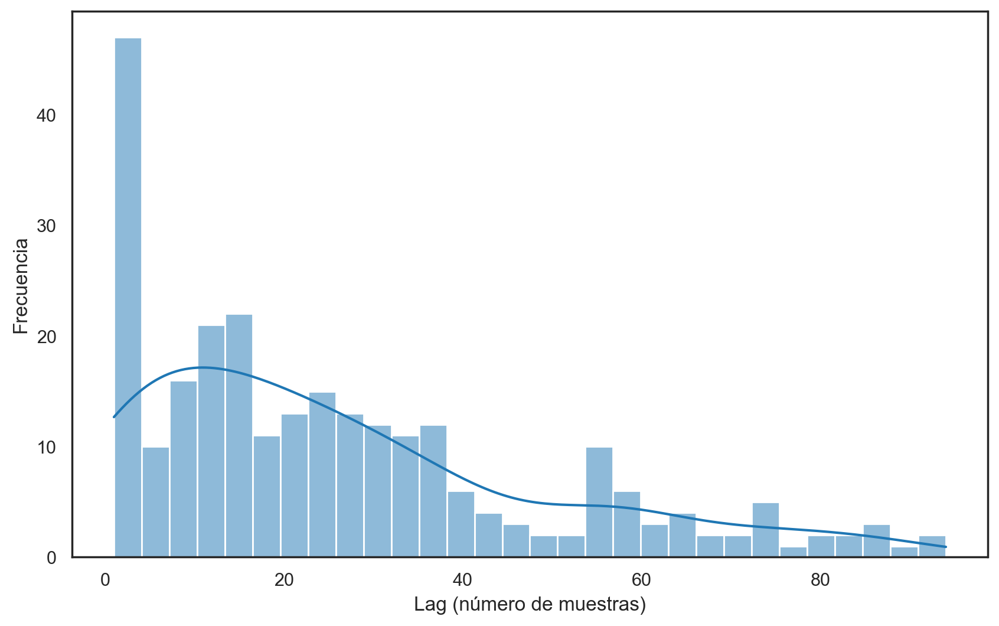

In [71]:
plt.figure(figsize=(10, 6))
g = sns.histplot(df_memoria['lag'], bins=30, kde=True)
plt.xlabel('Lag (número de muestras)')
plt.ylabel('Frecuencia')
plt.show()


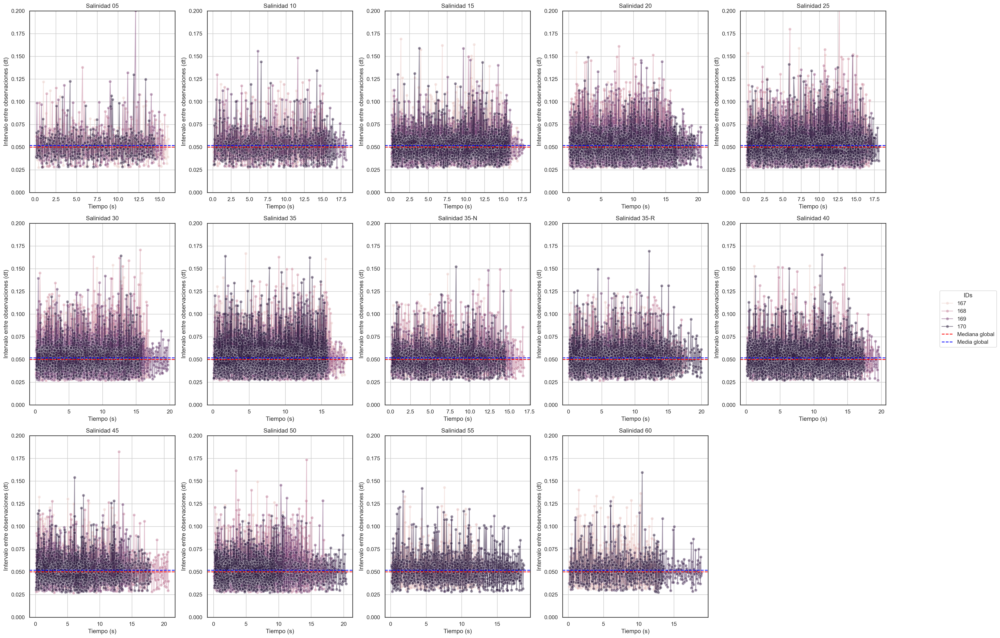

In [69]:
# Obtener lista de salinidades ORDENADAS usando tu función
salinidades = orden_salinidades(df)  # <--- Cambio clave aquí

# Crear una figura con subgráficos (layout 5x3 para 14 gráficos)
fig, axs = plt.subplots(3, 5, figsize=(25, 18))
axs = axs.flatten()

# Crear un gráfico por cada salinidad (ahora en orden)
for i, salinidad in enumerate(salinidades):
    # Filtrar datos para la salinidad actual
    df_sal = df[df['salinidad'] == salinidad]
    
    # Crear gráfico en el eje correspondiente
    sns.lineplot(data=df_sal, x='t', y='dt', hue='id', 
                 marker='o', alpha=0.5, ax=axs[i])
    
    # Líneas de referencia globales
    axs[i].axhline(y=df['dt'].median(), color='red', linestyle='--', label='Mediana global')
    axs[i].axhline(y=df['dt'].mean(), color='blue', linestyle='--', label='Media global')
    
    # Configuraciones del gráfico
    axs[i].set_title(f'Salinidad {salinidad}')
    axs[i].set_xlabel("Tiempo (s)")
    axs[i].set_ylabel("Intervalo entre observaciones (dt)")
    axs[i].set_ylim(0, 0.2)
    axs[i].grid(True)
    axs[i].legend().remove()

# Ocultar ejes vacíos
for j in range(len(salinidades), len(axs)):
    axs[j].axis('off')

# Añadir leyenda general
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, title='IDs', 
           bbox_to_anchor=(1.05, 0.5), loc='center left')

plt.tight_layout()
plt.show()